C:\Users\Arjun Goel\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Confusion Matrix:
[[92 13]
 [21 53]]


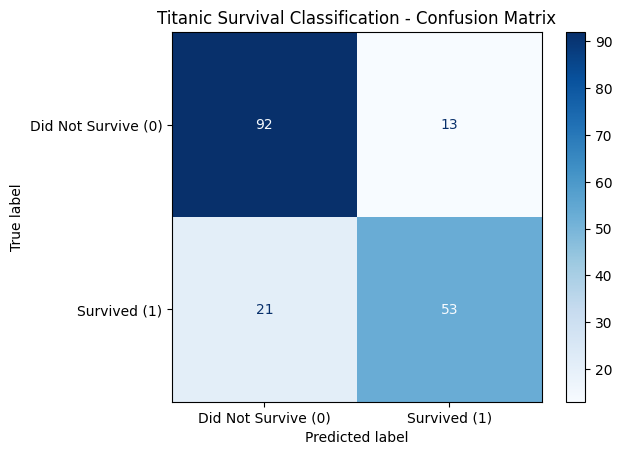

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# 2. Select relevant features and handle missing values
# We use pclass, sex, age, sibsp, parch, and fare to predict survival
features = ["pclass", "sex", "age", "sibsp", "parch", "fare"]
data = df[features + ["survived"]].copy()

# Convert categorical 'sex' column to numeric (0 for female, 1 for male)
data["sex"] = data["sex"].map({"female": 0, "male": 1})

# Fill missing age values with the median age
data["age"] = data["age"].fillna(data["age"].median())

# Drop any remaining rows with missing values
data = data.dropna()

# 3. Define features (X) and target variable (y)
X = data[features]
y = data["survived"]

# 4. Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Train a Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# 6. Make predictions on the test set
y_pred = model.predict(X_test)

# 7. Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# 8. Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Did Not Survive (0)", "Survived (1)"]
)
disp.plot(cmap=plt.cm.Blues)
plt.title("Titanic Survival Classification - Confusion Matrix")
plt.show()

## Task 39: Confusion Matrix Analysis

A confusion matrix is a tabular summary used to evaluate the performance of a classification model. It compares the actual ground truth labels against the predictions made by the model, breaking them down into four distinct categories:

- **True Positive (TP):** The model correctly predicted that a passenger survived (predicted positive, actual positive).
- **True Negative (TN):** The model correctly predicted that a passenger did not survive (predicted negative, actual negative).
- **False Positive (FP):** The model incorrectly predicted that a passenger survived when they actually did not (Type I error).
- **False Negative (FN):** The model incorrectly predicted that a passenger did not survive when they actually did (Type II error).

### Why Use a Confusion Matrix Instead of Accuracy?
While overall accuracy gives a general percentage of correct predictions, it can be misleading when dealing with imbalanced datasets (for example, if far more passengers perished than survived). A confusion matrix provides deeper visibility into exactly where the model is making errors, allowing us to evaluate metrics like precision, recall, and specificity depending on whether false positives or false negatives are more critical to minimize.

## Interview Questions and Answers

### Q1: What is a confusion matrix?
**Answer:** A confusion matrix is a table that summarizes the performance of a classification model on a set of test data where the true values are known. It cross-tabulates actual versus predicted classes, providing a clear breakdown of correct and incorrect predictions across each category.

### Q2: What is a True Positive?
**Answer:** A True Positive occurs when the model predicts a positive outcome and the actual ground truth is also positive. For instance, in the Titanic dataset, it means the model correctly predicted that a specific passenger survived.

### Q3: What is a False Positive?
**Answer:** A False Positive occurs when the model predicts a positive outcome, but the actual ground truth is negative (also known as a Type I error). For instance, the model predicted a passenger survived, but they actually did not survive.

### Q4: Why can a confusion matrix be more informative than accuracy?
**Answer:** Accuracy only provides a single ratio of correct predictions over total predictions, which can be highly deceptive if classes are imbalanced. A confusion matrix separates errors into false positives and false negatives, revealing specific weaknesses in the model and enabling calculation of precision, recall, and F1-score for better decision-making.